In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, recall_score, precision_score,
    f1_score, roc_curve, roc_auc_score, classification_report
)

In [3]:
df = pd.read_csv(r"C:\pandas\online food delivery dataset.csv")
df.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    str    
 2   Marital Status              388 non-null    str    
 3   Occupation                  388 non-null    str    
 4   Monthly Income              388 non-null    str    
 5   Educational Qualifications  388 non-null    str    
 6   Family size                 388 non-null    int64  
 7   Customer Type               388 non-null    str    
 8   latitude                    388 non-null    float64
 9   longitude                   388 non-null    float64
 10  Pin code                    388 non-null    int64  
 11  Output                      388 non-null    str    
 12  Feedback                    388 non-null    str    
 13  Unnamed: 13                 388 non-null    st

In [5]:
df.columns

Index(['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income',
       'Educational Qualifications', 'Family size', 'Customer Type',
       'latitude', 'longitude', 'Pin code', 'Output', 'Feedback',
       'Unnamed: 13'],
      dtype='str')

In [6]:
df.describe()

,Age,Family size,latitude,longitude,Pin code
count,388.000000,388.000000,388.000000,388.000000,388.000000
mean,24.628866,3.280928,12.972058,77.600160,560040.113402
std,2.975593,1.351025,0.044489,0.051354,31.399609
min,18.000000,1.000000,12.865200,77.484200,560001.000000
25%,23.000000,2.000000,12.936900,77.565275,560010.750000
50%,24.000000,3.000000,12.977000,77.592100,560033.500000
75%,26.000000,4.000000,12.997025,77.630900,560068.000000
max,33.000000,6.000000,13.102000,77.758200,560109.000000


In [7]:
df.isnull().sum()

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64

In [8]:
df = df.drop(columns=["Unnamed: 13", "Pin code"])

text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].str.strip()

print("Shape:", df.shape)
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(df["Feedback"].value_counts())
print(df["Output"].value_counts())

Shape: (388, 12)
Missing: 0
Duplicates: 103
Feedback
Positive    317
Negative     71
Name: count, dtype: int64
Output
Yes    301
No      87
Name: count, dtype: int64


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("After drop duplicates:", df.shape)

After drop duplicates: (285, 12)


In [10]:
y = (df["Output"] == "Yes").astype(int)

X = df.drop("Output", axis=1)

print("Raw Features shape:", X.shape)
print("Target shape:", y.shape)
print("Text columns:", X.select_dtypes(include="object").columns.tolist())
print(y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("x_train:", X_train.shape)
print("x_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Raw Features shape: (285, 11)
Target shape: (285,)
Text columns: ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Customer Type', 'Feedback']
Output
1    217
0     68
Name: count, dtype: int64
x_train: (228, 11)
x_test : (57, 11)
y_train: (228,)
y_test : (57,)


C:\Users\20912023100033\AppData\Local\Temp\ipykernel_30660\591211000.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Text columns:", X.select_dtypes(include="object").columns.tolist())


In [11]:
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print("After encoding -> X_train:", X_train.shape)
print("After encoding -> X_test :", X_test.shape)
print("Text columns remaining in train:",
      X_train.select_dtypes(include="object").columns.tolist())
print("Text columns remaining in test :",
      X_test.select_dtypes(include="object").columns.tolist())

assert list(X_train.columns) == list(X_test.columns), "Columns mismatch!"

After encoding -> X_train: (228, 21)
After encoding -> X_test : (57, 21)
Text columns remaining in train: []
Text columns remaining in test : []


In [12]:
correlation = X_train.corr(numeric_only=True)
correlation

,Age,Family size,latitude,longitude,Gender_Male,Marital Status_Prefer not to say,Marital Status_Single,Occupation_House wife,Occupation_Self Employeed,Occupation_Student,...,Monthly Income_Below Rs.10000,Monthly Income_More than 50000,Monthly Income_No Income,Educational Qualifications_Ph.D,Educational Qualifications_Post Graduate,Educational Qualifications_School,Educational Qualifications_Uneducated,Customer Type_New,Customer Type_Regular,Feedback_Positive
Age,1.000000,0.201948,0.056765,0.047682,-0.031932,0.156052,-0.683860,0.366801,0.198760,-0.655245,...,-0.084991,0.367374,-0.424969,0.175705,-0.157137,0.236637,0.155607,0.015667,-0.149776,-0.144028
Family size,0.201948,1.000000,-0.068112,0.068150,-0.134726,-0.072340,-0.231312,0.222509,0.070609,-0.101159,...,-0.104942,0.138198,0.012194,0.047772,-0.099530,0.206091,-0.013156,-0.454941,-0.589924,0.046525
latitude,0.056765,-0.068112,1.000000,-0.170688,-0.057021,0.136506,-0.062251,0.094532,0.092127,-0.008715,...,-0.004558,-0.031752,0.023559,-0.024859,-0.001576,0.034182,0.064704,0.031288,0.043386,-0.121471
longitude,0.047682,0.068150,-0.170688,1.000000,-0.041992,-0.038340,-0.022825,-0.063418,0.024486,-0.207745,...,-0.009436,0.032335,-0.168130,0.034799,-0.102311,-0.011611,-0.044607,-0.037457,-0.066027,0.091990
Gender_Male,-0.031932,-0.134726,-0.057021,-0.041992,1.000000,-0.007488,0.091795,-0.244244,0.068864,0.012922,...,-0.002235,0.147461,-0.077885,-0.026841,-0.032387,-0.060910,-0.079967,0.053326,0.090613,-0.080750
Marital Status_Prefer not to say,0.156052,-0.072340,0.136506,-0.038340,-0.007488,1.000000,-0.256742,0.094492,0.077757,-0.182719,...,0.046272,0.059580,-0.116415,0.065885,0.046020,-0.036079,-0.011812,0.150171,-0.050907,-0.109178
Marital Status_Single,-0.683860,-0.231312,-0.062251,-0.022825,0.091795,-0.256742,1.000000,-0.292445,-0.326286,0.636718,...,0.054117,-0.431684,0.445386,-0.193134,0.278735,-0.244337,-0.095748,0.007077,0.155030,0.144728
Occupation_House wife,0.366801,0.222509,0.094532,-0.063418,-0.244244,0.094492,-0.292445,1.000000,-0.080417,-0.208128,...,-0.057542,-0.089224,0.215576,-0.049848,-0.180783,0.537291,0.327407,-0.055692,-0.142485,0.040154
Occupation_Self Employeed,0.198760,0.070609,0.092127,0.024486,0.068864,0.077757,-0.326286,-0.080417,1.000000,-0.407267,...,-0.112598,0.311288,-0.373033,0.068014,-0.199194,0.182451,-0.026329,-0.008789,0.034238,-0.103156
Occupation_Student,-0.655245,-0.101159,-0.008715,-0.207745,0.012922,-0.182719,0.636718,-0.208128,-0.407267,1.000000,...,0.076041,-0.428073,0.757694,-0.063238,0.285664,-0.208128,-0.068143,-0.007232,0.040582,0.180929


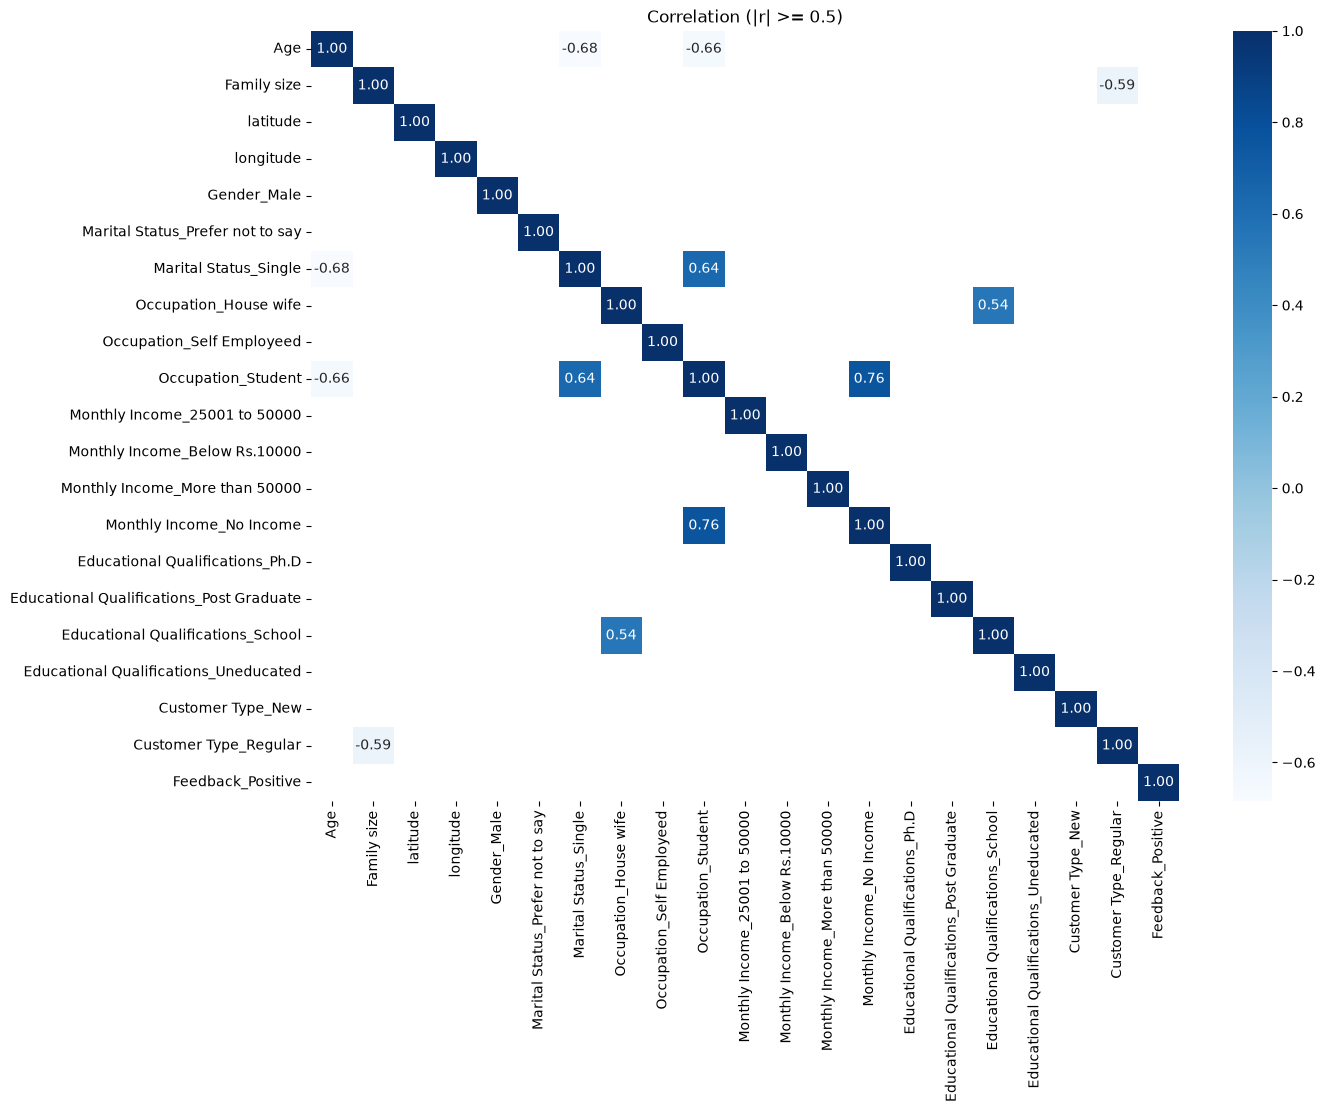

In [13]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=correlation.abs() < 0.5
)

plt.title("Correlation (|r| >= 0.5)")
plt.show()

In [14]:
stand = StandardScaler()

x_train_scaler = pd.DataFrame(
    stand.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

x_test_scaler = pd.DataFrame(
    stand.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("x_train_scaler:", x_train_scaler.shape)
print("x_test_scaler :", x_test_scaler.shape)

x_train_scaler: (228, 21)
x_test_scaler : (57, 21)


In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

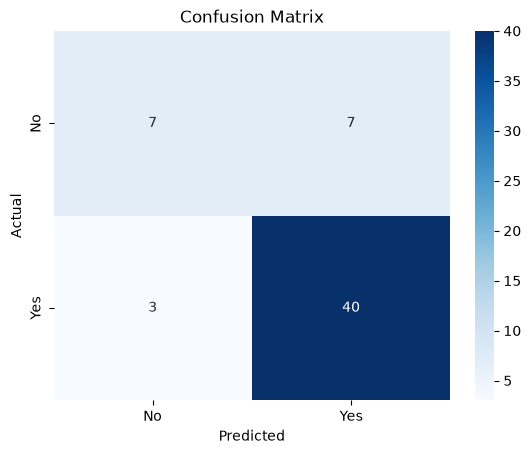

Test Accuracy : 0.8246
Test Recall   : 0.9302
Test Precision: 0.8511
Test F1_Score : 0.8889

               precision    recall  f1-score   support

          No       0.70      0.50      0.58        14
         Yes       0.85      0.93      0.89        43

    accuracy                           0.82        57
   macro avg       0.78      0.72      0.74        57
weighted avg       0.81      0.82      0.81        57



In [16]:
# Confusion Matrix
conf = confusion_matrix(y_test, y_pred)
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Metrics
print(f"Test Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Test F1_Score : {f1_score(y_test, y_pred):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["No", "Yes"]))

ROC-AUC: 0.7990033222591363


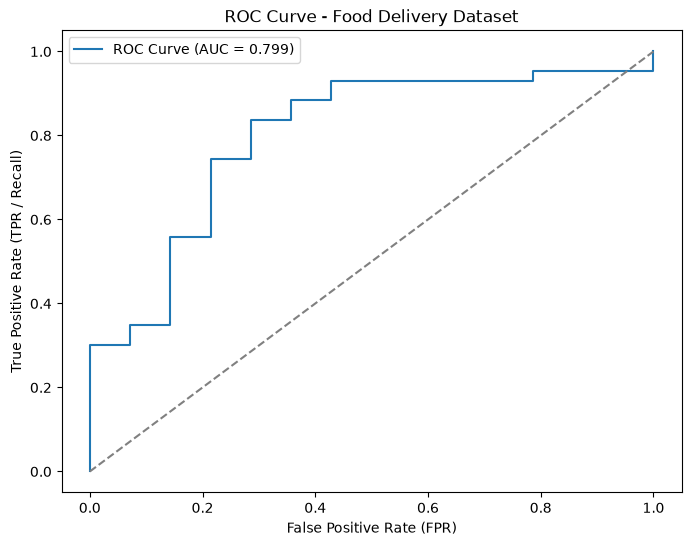

In [17]:
y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR / Recall)")
plt.title("ROC Curve - Food Delivery Dataset")
plt.legend()
plt.show()

In [18]:
forward = SequentialFeatureSelector(
    estimator=LogisticRegression(max_iter=1000),
    n_features_to_select=8,
    direction="forward"
)

x_train_forward = forward.fit_transform(x_train_scaler, y_train)
x_test_forward  = forward.transform(x_test_scaler)

print("x_train_forward:", x_train_forward.shape)
print("x_test_forward :", x_test_forward.shape)

selected_forward_cols = x_train_scaler.columns[forward.get_support()]
print("Selected features:", list(selected_forward_cols))

x_train_forward: (228, 8)
x_test_forward : (57, 8)
Selected features: ['Age', 'Family size', 'latitude', 'Marital Status_Prefer not to say', 'Marital Status_Single', 'Occupation_Student', 'Monthly Income_Below Rs.10000', 'Feedback_Positive']
